In [1]:
# ЛР-3. Цуркан Еріка. Варіант 7 (17)
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

In [2]:
## 1.
# вартості варіанта 7 з README: виїзд 1800, відмова 60000

COST_VISIT = 1800
COST_FAILURE = 60000

registry = pd.read_csv("registry.csv")
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("registry:", registry.shape, "| train:", train.shape, "| test:", test.shape)
display(train.head())
print("частка failed у train:", round(train["failed"].mean(), 4))

registry: (6000, 8) | train: (4023, 20) | test: (1977, 19)


,object_id,load_mean,load_std,load_stability,load_weekend_ratio,temp_rise_mean,temp_rise_std,temp_rise_median,pd_mean,pd_std,pd_stability,pd_per_load,temp_per_load,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor,failed
0,EQ100001,80.747,11.030,0.8798,0.8166,14.116,1.011,14.090,35.372,7.502,0.8250,0.4381,0.1748,switchgear,kv6,north,2015,2019,0,0
1,EQ100006,73.220,9.341,0.8869,0.7827,34.596,2.914,35.380,66.827,13.234,0.8347,0.9127,0.4725,switchgear,kv10,west,2016,2018,0,0
2,EQ100007,40.589,6.435,0.8632,0.8179,15.880,1.122,16.065,92.820,15.291,0.8586,2.2868,0.3912,switchgear,kv35,south,2019,2023,0,0
3,EQ100008,23.336,3.888,0.8572,0.7729,10.512,0.611,10.580,36.609,8.019,0.8203,1.5688,0.4505,meter_unit,kv35,west,2020,2020,0,0
4,EQ100009,72.511,10.793,0.8704,0.8024,18.943,1.642,19.370,33.031,7.733,0.8103,0.4555,0.2612,switchgear,kv6,centre,1979,2018,0,0


частка failed у train: 0.0557


In [3]:
## 2. Витік (M-1)
# AUC кожної числової колонки окремо; якщо < 0.5 => 1 - AUC; > 0.9 => витік

num_cols = train.select_dtypes("number").columns.drop("failed")
auc = pd.Series({col: roc_auc_score(train["failed"], train[col]) for col in num_cols})
auc = auc.where(auc >= 0.5, 1 - auc).sort_values(ascending=False)
print(auc.round(4))

leak = auc[auc > 0.9].index.tolist()
print("витік:", leak)
train = train.drop(columns=leak)
test = test.drop(columns=leak, errors="ignore")

temp_rise_std         0.8241
temp_rise_median      0.8215
temp_rise_mean        0.8212
pd_mean               0.7514
pd_std                0.7468
load_mean             0.6694
load_std              0.6691
temp_per_load         0.6675
pd_per_load           0.6074
install_year          0.5595
load_weekend_ratio    0.5313
outdoor               0.5270
load_stability        0.5187
pd_stability          0.5114
last_overhaul_year    0.5047
dtype: float64
витік: []


In [4]:
## 3. Зміщена вибірка (M-2)
# частка history-об'єктів, що є в train; < 0.9 => вибірка зміщена

history = registry[registry["cohort"] == "history"]
share = len(train) / len(history)
print("рядків train:", len(train), "| об'єктів history:", len(history), "| частка:", round(share, 4))

if share < 0.9:
    in_train = history["object_id"].isin(train["object_id"])
    print("середній install_year: є в train", round(history.loc[in_train, "install_year"].mean(), 2),
          "| немає в train", round(history.loc[~in_train, "install_year"].mean(), 2))
else:
    print("у train є всі об'єкти history => вибірка не зміщена")

рядків train: 4023 | об'єктів history: 4023 | частка: 1.0
у train є всі об'єкти history => вибірка не зміщена


In [5]:
## 4. Зсув у часі (M-3)
# (середнє test - середнє train) / std train; > 0.5 => стандартизуємо temp окремо в train і test

temp = ["temp_rise_mean", "temp_rise_std", "temp_rise_median", "temp_per_load"]

shift = (test["temp_rise_mean"].mean() - train["temp_rise_mean"].mean()) / train["temp_rise_mean"].std()
print("зсув temp_rise_mean:", round(shift, 4))

if shift > 0.5:
    train[temp] = (train[temp] - train[temp].mean()) / train[temp].std()
    test[temp] = (test[temp] - test[temp].mean()) / test[temp].std()
    print("temp стандартизовано окремо в train і test")

зсув temp_rise_mean: 0.9207
temp стандартизовано окремо в train і test


In [6]:
## 5.
# one-hot для категорій, 25% на валідацію зі stratify, стандартизація за X_tr

categorical = ["equipment_type", "voltage_class", "region"]

X = pd.get_dummies(train.drop(columns=["object_id", "failed"]), columns=categorical, dtype=float)
X_test = pd.get_dummies(test.drop(columns=["object_id"]), columns=categorical, dtype=float)[X.columns]
y = train["failed"]

X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

scaler = StandardScaler().fit(X_tr)
X_tr, X_va, X_te = scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_test)
print("X:", X.shape, "| X_tr:", X_tr.shape, "| X_va:", X_va.shape, "| X_te:", X_te.shape)

X: (4023, 25) | X_tr: (3017, 25) | X_va: (1006, 25) | X_te: (1977, 25)


In [7]:
## 6. Моделі
# PR-AUC на навчальній і валідаційній частині, порівнюємо з часткою відмов

models = {
    "дерево рішень": DecisionTreeClassifier(max_depth=5, random_state=0),
    "опорні вектори": CalibratedClassifierCV(SVC(), ensemble=False),
    "найближчі сусіди": KNeighborsClassifier(n_neighbors=25),
    "наївний Баєс": GaussianNB(),
    "перцептрон": MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=1000, random_state=0),
}


def pr_auc(model):
    model.fit(X_tr, y_tr)
    return (average_precision_score(y_tr, model.predict_proba(X_tr)[:, 1]),
            average_precision_score(y_va, model.predict_proba(X_va)[:, 1]))


scores = pd.DataFrame([(name, *pr_auc(model)) for name, model in models.items()],
                      columns=["модель", "PR-AUC train", "PR-AUC val"]).set_index("модель")
display(scores.sort_values("PR-AUC val", ascending=False).round(4))
print("частка відмов у y_va:", round(y_va.mean(), 4))
print("найкраща на валідації:", scores["PR-AUC val"].idxmax())

,PR-AUC train,PR-AUC val
модель,,
перцептрон,0.4359,0.2889
наївний Баєс,0.3234,0.2735
опорні вектори,0.7999,0.2698
найближчі сусіди,0.3514,0.2561
дерево рішень,0.4994,0.1411


частка відмов у y_va: 0.0557
найкраща на валідації: перцептрон


,PR-AUC train,PR-AUC val,розрив
alpha,,,
0.0001,0.8504,0.2316,0.6188
0.0010,0.8639,0.1972,0.6668
0.0100,0.6399,0.2517,0.3881
0.1000,0.6261,0.2591,0.3670
1.0000,0.4359,0.2889,0.1471


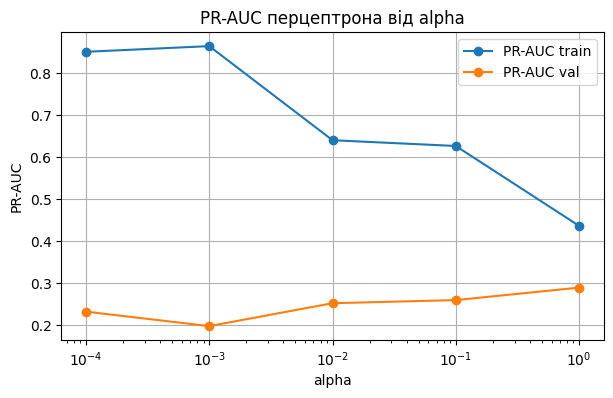

In [8]:
## 7. Перенавчання перцептрона
# той самий перцептрон з різним alpha; менший alpha => слабший штраф

alphas = [0.0001, 0.001, 0.01, 0.1, 1.0]

curve = pd.DataFrame(
    [pr_auc(MLPClassifier(hidden_layer_sizes=(32,), alpha=a, max_iter=1000, random_state=0)) for a in alphas],
    index=pd.Index(alphas, name="alpha"), columns=["PR-AUC train", "PR-AUC val"])
curve["розрив"] = curve["PR-AUC train"] - curve["PR-AUC val"]
display(curve.round(4))

curve[["PR-AUC train", "PR-AUC val"]].plot(marker="o", logx=True, grid=True, figsize=(7, 4), title="PR-AUC перцептрона від alpha")
plt.ylabel("PR-AUC")
plt.show()

In [9]:
## 8. Правило рішення
# їхати, якщо p >= COST_VISIT / COST_FAILURE; порівнюємо з порогом 0.5 і «перевірити всіх»

threshold = COST_VISIT / COST_FAILURE
p_va = models["перцептрон"].predict_proba(X_va)[:, 1]
fact = y_va.to_numpy()

print("поріг з вартостей:", threshold)
print("середня ймовірність:", round(p_va.mean(), 4), "| частка відмов у y_va:", round(fact.mean(), 4))


def effect(go):
    nobody = fact.sum() * COST_FAILURE
    plan = go.sum() * COST_VISIT + (fact & ~go).sum() * COST_FAILURE
    return nobody - plan


rules = {
    f"поріг з вартостей = {threshold}": p_va >= threshold,
    "поріг 0.5": p_va >= 0.5,
    "перевірити всіх": np.ones(len(p_va), dtype=bool),
}
display(pd.DataFrame({"на виїзд": [go.sum() for go in rules.values()],
                      "ефект, грн": [effect(go) for go in rules.values()]}, index=rules.keys()))

поріг з вартостей: 0.03
середня ймовірність: 0.0596 | частка відмов у y_va: 0.0557


,на виїзд,"ефект, грн"
поріг з вартостей = 0.03,442,1844400
поріг 0.5,14,454800
перевірити всіх,1006,1549200


In [10]:
## 9. Рішення й самоперевірка
# p на X_te >= порога => 1, інакше 0

decision = (models["перцептрон"].predict_proba(X_te)[:, 1] >= threshold).astype(int)

submission = pd.DataFrame({"object_id": test["object_id"], "decision": decision})

assert (COST_VISIT, COST_FAILURE) in [(1800, 60000), (2750, 50000), (4080, 48000), (5500, 50000)], "вартості — з таблиці README"
assert all(max(a, 1 - a) <= 0.9 for a in (roc_auc_score(y, X[c]) for c in X.columns)), "в ознаках лишилася колонка з AUC понад 0.9"
assert list(X_test.columns) == list(X.columns), "колонки X_test мають збігатися з X"
assert len(X_va) == int(np.ceil(len(train) * 0.25)), "валідаційна частина — 25% train"
assert np.allclose(np.mean(X_tr, axis=0), 0) and np.allclose(np.std(X_tr, axis=0), 1), "X_tr не стандартизовано"
assert len(submission) == len(test) and submission["object_id"].is_unique, "має бути рядок на кожен об'єкт test"
assert pd.api.types.is_integer_dtype(submission["decision"]) and submission["decision"].isin([0, 1]).all(), "decision — цілі 0 або 1, а не True/False"
assert 0.02 <= submission["decision"].mean() <= 0.9, "на виїзд менше 2% або більше 90% об'єктів: перевірте поріг"

submission.to_csv("submission.csv", index=False)
print("усе гаразд: на виїзд", int(submission["decision"].sum()), "з", len(submission))

усе гаразд: на виїзд 895 з 1977
